# CODE 2.1: Explore How a Healthy Compressor Works

> **Goal:** learn what *normal* looks like before we build any model, and use it to make three decisions for notebook 3.1:
>
> 1. How long is one window (the piece of time a model judges at once)?
> 2. Which signals change by themselves over the weeks, so the models should not see their raw level?
> 3. Which signals do we keep?
>
> - **Input:** `data/processed/metropt3.parquet` (notebook 1.1) and `results/time_split.csv` (notebook 1.2).
> - **Output:** no files. Charts, numbers, and the decisions in the Summary.
>
> **Only February and March** (train and validation) are loaded. The test months stay closed until notebook 5.2.

### Words Used in This Notebook

> - **Pump phase:** the compressor pushes air into the tanks. Then `DV_eletric` = 1 and the pressure goes up.
> - **Rest phase:** the compressor does not pump. The train keeps using air for its brakes and doors, so the pressure slowly goes down.
> - **Pump cycle:** one rest phase plus one pump phase, from one pump start to the next.
> - **Window:** a piece of the recording, for example the last 60 minutes. A model looks at one window and says how normal it is. Notebook 3.1 explains windows in detail.
> - **Drift:** "normal" slowly changes over time, for example because the weather gets warmer.
> - **Median:** the middle value: half of the values are below it, half above. Unlike the average, one extreme value does not pull it away.
> - **Correlation:** how much two signals move together, from -1 (always opposite) through 0 (unrelated) to 1 (always together).

## Import Libraries & Variables

### Import Libraries

> - `os`: works with folders and file paths.
> - `numpy`: works with numbers and arrays.
> - `pandas`: works with tables and times.
> - `matplotlib`: draws charts. `matplotlib.dates` writes times under a time axis.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

### Variables

#### Folder Paths

> - `ROOT_DIR`: the main project folder (the folder with `requirements.txt`).
> - `PARQUET_FILE`: the sensor data from notebook 1.1.
> - `SPLIT_FILE`: the time split from notebook 1.2. We read where validation ends from it, so this notebook uses exactly the same boundary.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PARQUET_FILE = os.path.join(ROOT_DIR, "data", "processed", "metropt3.parquet")
SPLIT_FILE = os.path.join(ROOT_DIR, "results", "time_split.csv")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `GAP_SECONDS`: as in notebooks 1.1 and 1.2, a step of more than 60 seconds is a gap.
> - `DAY_TO_SHOW`, `ZOOM_FROM`, `ZOOM_TO`: one ordinary weekday in February, and one hour of it, to look at closely. Any normal weekday would do.
> - `PUMPING_AMPS`: from 4.5 A up, the motor is pumping (we check this below).
> - `WINDOW_MINUTES`: the window lengths we compare.
> - `STEP_MINUTES`: a new window every 5 minutes, as planned.
> - `ANALOG_COLUMNS`, `DIGITAL_COLUMNS`: the 7 numbers and the 8 on/off signals.
> - `MONTH_COLORS`: February in the train color, March in the validation color of notebook 1.2.

In [3]:
GAP_SECONDS = 60
DAY_TO_SHOW = "2020-02-12"
ZOOM_FROM = "2020-02-12 10:00"
ZOOM_TO = "2020-02-12 11:10"
PUMPING_AMPS = 4.5
WINDOW_MINUTES = [30, 45, 60, 90]
STEP_MINUTES = 5
ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
MONTH_COLORS = {"February": "#1D9E75", "March": "#534AB7"}

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Find Every Pump Phase

> `find_pumps()` walks through the readings and finds every pump phase: the row where `DV_eletric` turns from 0 to 1 (start) and the next row where it turns back to 0 (end). For each pump phase it also measures the rest phase after it, up to the next pump start.
>
> A pump cycle only counts when its start, its end and the next start are in **one stretch of data without a gap**. Otherwise the train was switched off in between, and the times would be wrong.
>
> It returns one row per pump phase:
>
> - `start`: when the pump phase started.
> - `pump_minutes`: how long it pumped.
> - `bar_at_start`, `bar_at_end`: the tank pressure (`Reservoirs`) when pumping started and stopped.
> - `rest_minutes`: how long the rest phase after it lasted.
> - `drop_per_minute`: how fast the tank pressure fell during that rest phase, in bar per minute.

In [5]:
def find_pumps(df, gap_seconds):
    times = df["timestamp"].to_numpy()
    pressure = df["Reservoirs"].to_numpy()
    pumping = df["DV_eletric"].to_numpy().astype(int)
    stretch = np.cumsum(np.r_[0, np.diff(times).astype("timedelta64[s]").astype(int) > gap_seconds])
    change = np.diff(pumping, prepend=pumping[0])
    starts = np.flatnonzero(change == 1)
    ends = np.flatnonzero(change == -1)

    rows = []
    for start, next_start in zip(starts[:-1], starts[1:]):
        end = ends[np.searchsorted(ends, start)]
        if not stretch[start] == stretch[end] == stretch[next_start]:
            continue
        rest_minutes = (times[next_start] - times[end]) / np.timedelta64(1, "m")
        rows.append({"start": times[start],
                     "pump_minutes": (times[end] - times[start]) / np.timedelta64(1, "m"),
                     "bar_at_start": pressure[start],
                     "bar_at_end": pressure[end],
                     "rest_minutes": rest_minutes,
                     "drop_per_minute": (pressure[end] - pressure[next_start]) / rest_minutes})
    return pd.DataFrame(rows)

### Count Pump Starts per Window

> `pump_starts_per_window()` makes a window that ends every `step_minutes`, each `window_minutes` long, and counts the pump starts inside. A window is left out, as notebook 3.1 will do, when it has a gap inside, or when it does not have readings right up to its start and its end.

In [6]:
def pump_starts_per_window(df, window_minutes, step_minutes, gap_seconds):
    times = df["timestamp"].to_numpy().astype("datetime64[s]").astype(np.int64)
    gap_ends = times[1:][np.diff(times) > gap_seconds]
    start_times = times[np.flatnonzero(np.diff(df["DV_eletric"].to_numpy().astype(int), prepend=0) == 1)]
    window_ends = np.arange(times[0] - times[0] % (step_minutes * 60) + step_minutes * 60, times[-1] + 1, step_minutes * 60)
    window_starts = window_ends - window_minutes * 60

    first_row = np.searchsorted(times, window_starts, side="left")
    last_row = np.searchsorted(times, window_ends, side="right") - 1
    complete = ((first_row < len(times)) & (times[np.minimum(first_row, len(times) - 1)] - window_starts < gap_seconds)
                & (last_row >= 0) & (window_ends - times[np.maximum(last_row, 0)] < gap_seconds))
    no_gap = np.searchsorted(gap_ends, window_starts, side="right") == np.searchsorted(gap_ends, window_ends, side="right")
    counts = np.searchsorted(start_times, window_ends, side="right") - np.searchsorted(start_times, window_starts, side="right")
    return counts[complete & no_gap]

## Load February and March

### Read the Data, Then Keep Only Train and Validation

> We read the end of the validation part from `time_split.csv` and keep only the readings before it. The check proves that not a single reading from the test months is in memory.

In [7]:
split_table = pd.read_csv(SPLIT_FILE)
look_until = pd.Timestamp(split_table.set_index("split").loc["validation", "until (not included)"])
test_from = pd.Timestamp(split_table.set_index("split").loc["test", "from"])

df_sensors = pd.read_parquet(PARQUET_FILE)
df_sensors = df_sensors[df_sensors["timestamp"] < look_until].reset_index(drop=True)
df_sensors["month"] = df_sensors["timestamp"].dt.month_name()

print(f"Readings loaded: {len(df_sensors):,}")
print("From", df_sensors["timestamp"].iloc[0], "to", df_sensors["timestamp"].iloc[-1])
print("Readings per month:", df_sensors["month"].value_counts().reindex(list(MONTH_COLORS)).to_dict(), "\n")

check("no reading from the test months is loaded", df_sensors["timestamp"].max() < test_from)

Readings loaded: 445,298
From 2020-02-01 00:00:00 to 2020-03-31 23:59:59
Readings per month: {'February': 214850, 'March': 230448} 

PASS  no reading from the test months is loaded


## A Day in the Life

### One Whole Day

> Four signals of one ordinary February day: the pressure in the air tanks, the current of the motor, whether the compressor pumps (`DV_eletric`), and the oil temperature. A blank stretch means no readings: the train was switched off.

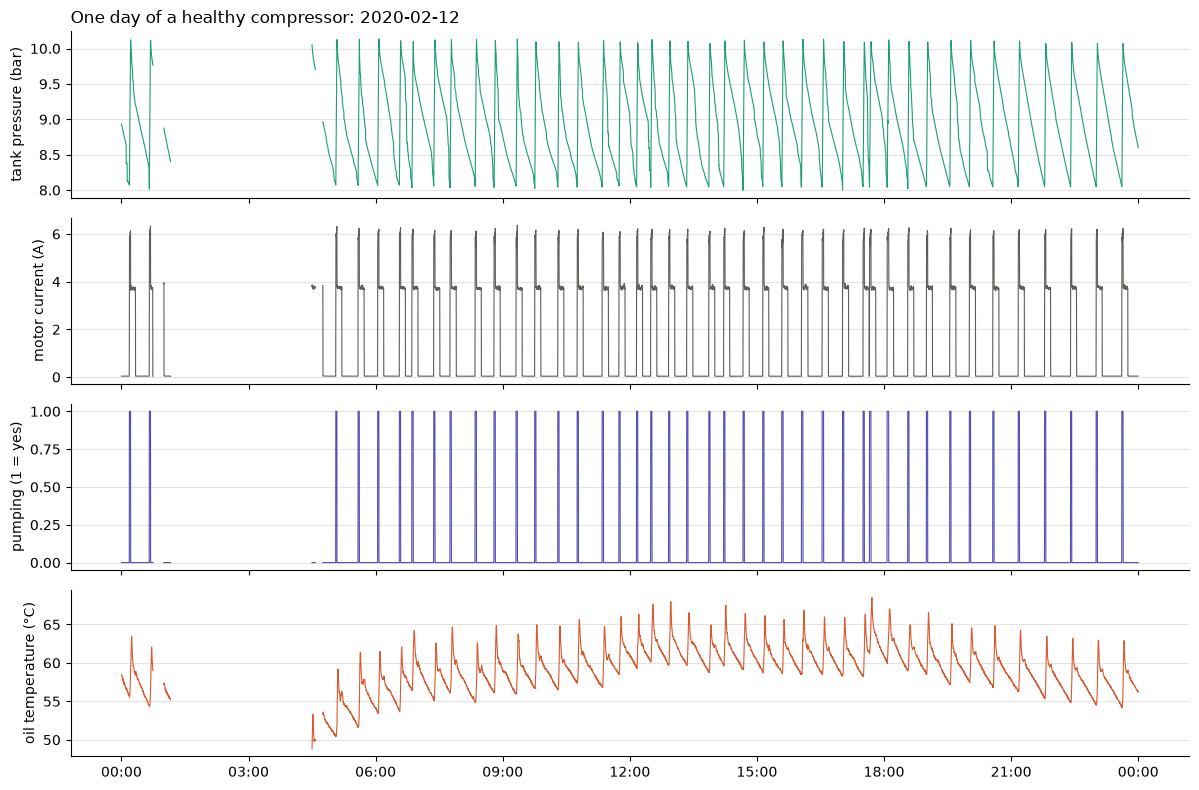

Readings on this day: 7,353, from 00:00 to 23:59


In [8]:
day = df_sensors[df_sensors["timestamp"].dt.strftime("%Y-%m-%d") == DAY_TO_SHOW].copy()
day["DV_eletric"] = day["DV_eletric"].astype(float)
day.loc[day["timestamp"].diff().dt.total_seconds() > GAP_SECONDS, ANALOG_COLUMNS + ["DV_eletric"]] = np.nan

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
panels = [("Reservoirs", "tank pressure (bar)", "#1D9E75"), ("Motor_current", "motor current (A)", "#5F5E5A"),
          ("DV_eletric", "pumping (1 = yes)", "#534AB7"), ("Oil_temperature", "oil temperature (°C)", "#D85A30")]
for ax, (column, label, color) in zip(axes, panels):
    ax.plot(day["timestamp"], day[column], color=color, linewidth=0.8)
    ax.set_ylabel(label)
    ax.grid(axis="y", color="#E5E4DF")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[0].set_title(f"One day of a healthy compressor: {DAY_TO_SHOW}", loc="left")
plt.tight_layout()
plt.show()
print(f"Readings on this day: {len(day):,}, from {day['timestamp'].min():%H:%M} to {day['timestamp'].max():%H:%M}")

> **What we see:** the tank pressure makes a **saw-tooth**: it slowly falls, then jumps up, again and again, all day. Every jump is a pump phase: the motor current goes up and `DV_eletric` turns to 1 at the same moments. The oil temperature jumps a little at every pump phase and cools down in between. Over the day it climbs from the start in the morning and falls again in the evening.

### One Hour Up Close

> The same day, zoomed in on about one hour. The colored bands are the pump phases.
>
> Think of a bicycle pump that keeps a tyre full while somebody keeps letting a little air out. Most of the time you rest and the tyre slowly gets softer (the **rest phase**). When it is too soft, you pump hard for a short time until it is full again (the **pump phase**). Then you rest again. The compressor does exactly this, by itself: it starts pumping at a low pressure and stops at a high one.

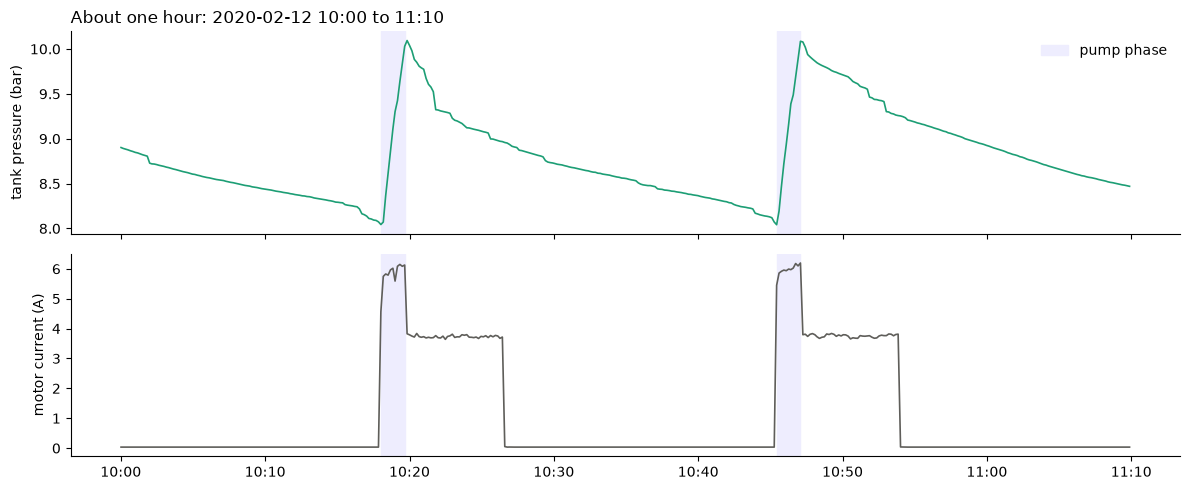

In [9]:
zoom = df_sensors[(df_sensors["timestamp"] >= ZOOM_FROM) & (df_sensors["timestamp"] <= ZOOM_TO)]
pumping = zoom["DV_eletric"].to_numpy() == 1

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, (column, label, color) in zip(axes, [("Reservoirs", "tank pressure (bar)", "#1D9E75"), ("Motor_current", "motor current (A)", "#5F5E5A")]):
    ax.fill_between(zoom["timestamp"], 0, 1, where=pumping, transform=ax.get_xaxis_transform(), color="#EEEDFE", step="post", label="pump phase")
    ax.plot(zoom["timestamp"], zoom[column], color=color, linewidth=1.2)
    ax.set_ylabel(label)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].legend(loc="upper right", frameon=False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[0].set_title(f"About one hour: {ZOOM_FROM} to {ZOOM_TO[-5:]}", loc="left")
plt.tight_layout()
plt.show()

> **What we see:** in each rest phase the pressure falls in a slow, almost straight line, with small steps down when the train uses a bit more air at once. Each pump phase is short: the pressure shoots up and the motor current jumps to its highest level. After each pump phase, the motor keeps turning for a few minutes without pumping (the middle level of the current), and then switches off.
>
> This picture is the heart of the project. An **air leak** makes the pressure fall faster during the rest phase, so the rest phases get shorter and the compressor has to pump more often.

## The Three Motor States

### How Much Current Does the Motor Use?

> A histogram counts how many readings fall into each small range of current (0.1 A wide). The y-axis uses a log scale (1, 10, 100, ...), so small and big counts both stay visible. The color shows whether the compressor was pumping (`DV_eletric` = 1) in those readings.

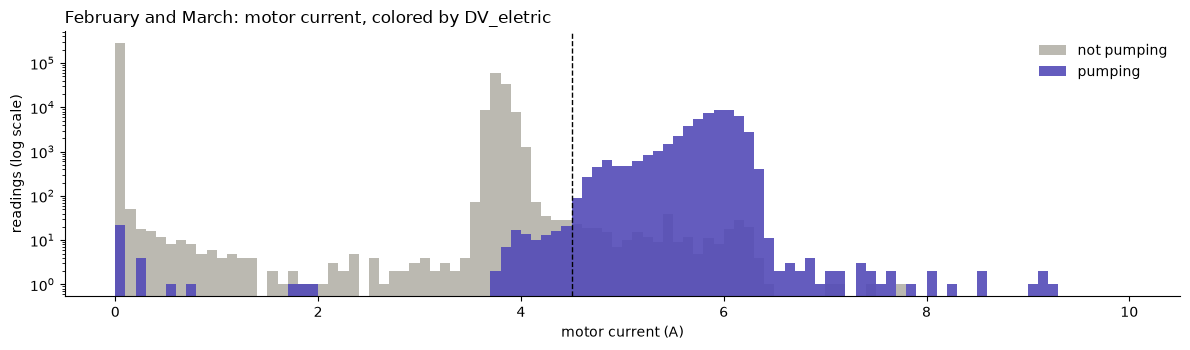

,% of readings,middle current (A),% with DV_eletric = 1
Motor_current,,,
off (below 1 A),62.8,0.04,0.0
"turning, not pumping (1 to 4.5 A)",25.3,3.78,0.1
pumping (above 4.5 A),11.9,5.90,99.5


Readings with DV_eletric = 1 that have a pumping current (above 4.5 A): 99.7%

PASS  DV_eletric agrees with the motor current: at least 95% of its pumping readings are above 4.5 A


In [10]:
bins = np.arange(0, 10.1, 0.1)
fig, ax = plt.subplots(figsize=(12, 3.6))
for value, label, color in [(0, "not pumping", "#B4B2A9"), (1, "pumping", "#534AB7")]:
    ax.hist(df_sensors.loc[df_sensors["DV_eletric"] == value, "Motor_current"], bins=bins, color=color, label=label, alpha=0.9)
ax.set_yscale("log")
ax.set_xlabel("motor current (A)")
ax.set_ylabel("readings (log scale)")
ax.axvline(PUMPING_AMPS, color="black", linewidth=1, linestyle="--")
ax.legend(frameon=False)
ax.set_title("February and March: motor current, colored by DV_eletric", loc="left")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

states = pd.cut(df_sensors["Motor_current"], bins=[-np.inf, 1, PUMPING_AMPS, np.inf], labels=["off (below 1 A)", f"turning, not pumping (1 to {PUMPING_AMPS} A)", f"pumping (above {PUMPING_AMPS} A)"])
state_table = pd.DataFrame({"% of readings": (states.value_counts(normalize=True) * 100).round(1),
                            "middle current (A)": df_sensors.groupby(states, observed=True)["Motor_current"].median().round(2),
                            "% with DV_eletric = 1": (df_sensors.groupby(states, observed=True)["DV_eletric"].mean() * 100).round(1)})
display(state_table)

pumping_rows = df_sensors[df_sensors["DV_eletric"] == 1]
share = (pumping_rows["Motor_current"] > PUMPING_AMPS).mean()
print(f"Readings with DV_eletric = 1 that have a pumping current (above {PUMPING_AMPS} A): {share * 100:.1f}%\n")
check("DV_eletric agrees with the motor current: at least 95% of its pumping readings are above 4.5 A", share >= 0.95)

> **What we see:** three clear groups, as the description says: off, turning without pumping, and pumping. The pumping group sits a little lower than the 7 A in the description, but it is clearly separate, and almost all of its readings have `DV_eletric` = 1. So `DV_eletric` is a reliable sign of pumping, and we use it to find the pump phases. A few readings above 7 A are the short start-up spike (the 9 A in the description): with one reading every 10 seconds, we rarely catch it.

## Pump Cycles in Numbers

### Every Pump Phase of February and March

> `find_pumps()` gives one row per pump phase. Then we compare the typical values of February and March.

In [11]:
pumps = find_pumps(df=df_sensors, gap_seconds=GAP_SECONDS)
pumps["month"] = pd.to_datetime(pumps["start"]).dt.month_name()
all_starts = int((np.diff(df_sensors["DV_eletric"].to_numpy().astype(int)) == 1).sum())
print(f"Pump starts in the data: {all_starts:,} | full pump cycles without a gap: {len(pumps):,}\n")

typical = pumps.groupby("month")[["pump_minutes", "rest_minutes", "bar_at_start", "bar_at_end", "drop_per_minute"]].median().reindex(list(MONTH_COLORS))
typical["pump_starts_per_hour"] = [len(pumps[pumps["month"] == month]) / (pumps.loc[pumps["month"] == month, ["pump_minutes", "rest_minutes"]].sum().sum() / 60) for month in MONTH_COLORS]
print("Middle value (median) of each month:")
display(typical.round(3))

Pump starts in the data: 2,876 | full pump cycles without a gap: 2,810

Middle value (median) of each month:


,pump_minutes,rest_minutes,bar_at_start,bar_at_end,drop_per_minute,pump_starts_per_hour
month,,,,,,
February,1.817,28.917,8.054,10.098,0.071,1.979
March,2.300,20.317,8.087,10.156,0.100,2.789


> **How to read the table:** a typical pump phase lasts about 2 minutes and fills the tanks from about 8 bar to about 10 bar (`bar_at_start`, `bar_at_end`). Then the compressor rests for many minutes while the pressure falls by about 2 bar. `pump_starts_per_hour` counts pump starts per hour of full cycles.

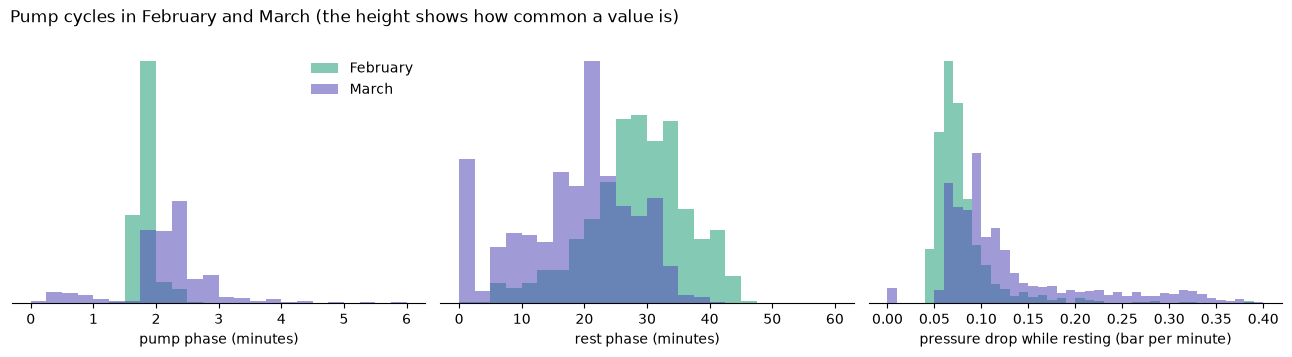

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (column, label, bins) in zip(axes, [("pump_minutes", "pump phase (minutes)", np.arange(0, 6.1, 0.25)),
                                             ("rest_minutes", "rest phase (minutes)", np.arange(0, 61, 2.5)),
                                             ("drop_per_minute", "pressure drop while resting (bar per minute)", np.arange(0, 0.41, 0.01))]):
    for month, color in MONTH_COLORS.items():
        ax.hist(pumps.loc[pumps["month"] == month, column], bins=bins, color=color, alpha=0.55, label=month, density=True)
    ax.set_xlabel(label)
    ax.set_yticks([])
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
axes[0].legend(frameon=False)
fig.suptitle("Pump cycles in February and March (the height shows how common a value is)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

> **What we see:** the two months do not have the same shape. In March the pump phases are a bit longer, the rest phases are shorter, and the pressure drops faster while resting. March also has some very short rest phases of a few minutes or less: at those times the compressor pumped almost without a break. That is more pumping, the same direction an air leak would push. We look at this more closely in "Did Normal Change Between February and March?" below.

## How Long Should a Window Be?

### Pump Starts per Window

> A model judges one window at a time. To notice that the compressor pumps *more often* than normal, a window must hold at least one **full pump cycle**: two pump starts, with a whole rest phase in between. The plan said 30 minutes, to be checked here.
>
> We make windows over February only (the train month), one every `STEP_MINUTES`, for each length in `WINDOW_MINUTES`, and count the pump starts in each.

In [13]:
train_part = df_sensors[df_sensors["timestamp"] < pd.Timestamp(split_table.set_index("split").loc["validation", "from"])]
rows = []
for minutes in WINDOW_MINUTES:
    counts = pump_starts_per_window(df=train_part, window_minutes=minutes, step_minutes=STEP_MINUTES, gap_seconds=GAP_SECONDS)
    rows.append({"window (minutes)": minutes, "windows": len(counts),
                 "% with 0 starts": round(np.mean(counts == 0) * 100, 1),
                 "% with 1 start": round(np.mean(counts == 1) * 100, 1),
                 "% with a full cycle (2 or more)": round(np.mean(counts >= 2) * 100, 1)})
window_table = pd.DataFrame(rows).set_index("window (minutes)")
display(window_table)

median_cycle = (pumps["pump_minutes"] + pumps["rest_minutes"]).median()
long_cycle = (pumps["pump_minutes"] + pumps["rest_minutes"]).quantile(0.99)
print(f"One full pump cycle (pump + rest): median {median_cycle:.1f} minutes, 99% are shorter than {long_cycle:.1f} minutes")

,windows,% with 0 starts,% with 1 start,% with a full cycle (2 or more)
window (minutes),,,,
30,6932,10.8,79.7,9.5
45,6860,0.0,54.2,45.8
60,6791,0.0,17.7,82.3
90,6653,0.0,0.0,100.0


One full pump cycle (pump + rest): median 25.8 minutes, 99% are shorter than 44.6 minutes


> **What we see:** a 30-minute window holds a full pump cycle only rarely, because one cycle alone takes almost that long. A 60-minute window holds a full cycle most of the time, and always at least one pump start. A 90-minute window always holds a full cycle, but it averages over a longer time, so a change shows up later, and the LSTM has to read half again as many time steps.
>
> **Decision: windows of 60 minutes, one every 5 minutes.** That is 360 readings of 10 seconds per window. A window with only one pump start is still useful: the features of notebook 3.1 measure the pressure drop over all resting minutes in the window, so they do not need a full cycle. One hour is also easy to explain: "the model always looks at the last hour".

## Did Normal Change Between February and March?

### Day by Day

> For every day we compute: how many pump starts per hour, the middle pump phase, the middle rest phase, the middle pressure drop while resting, and the middle oil temperature. The dashed line marks 1 March, the start of the validation month.

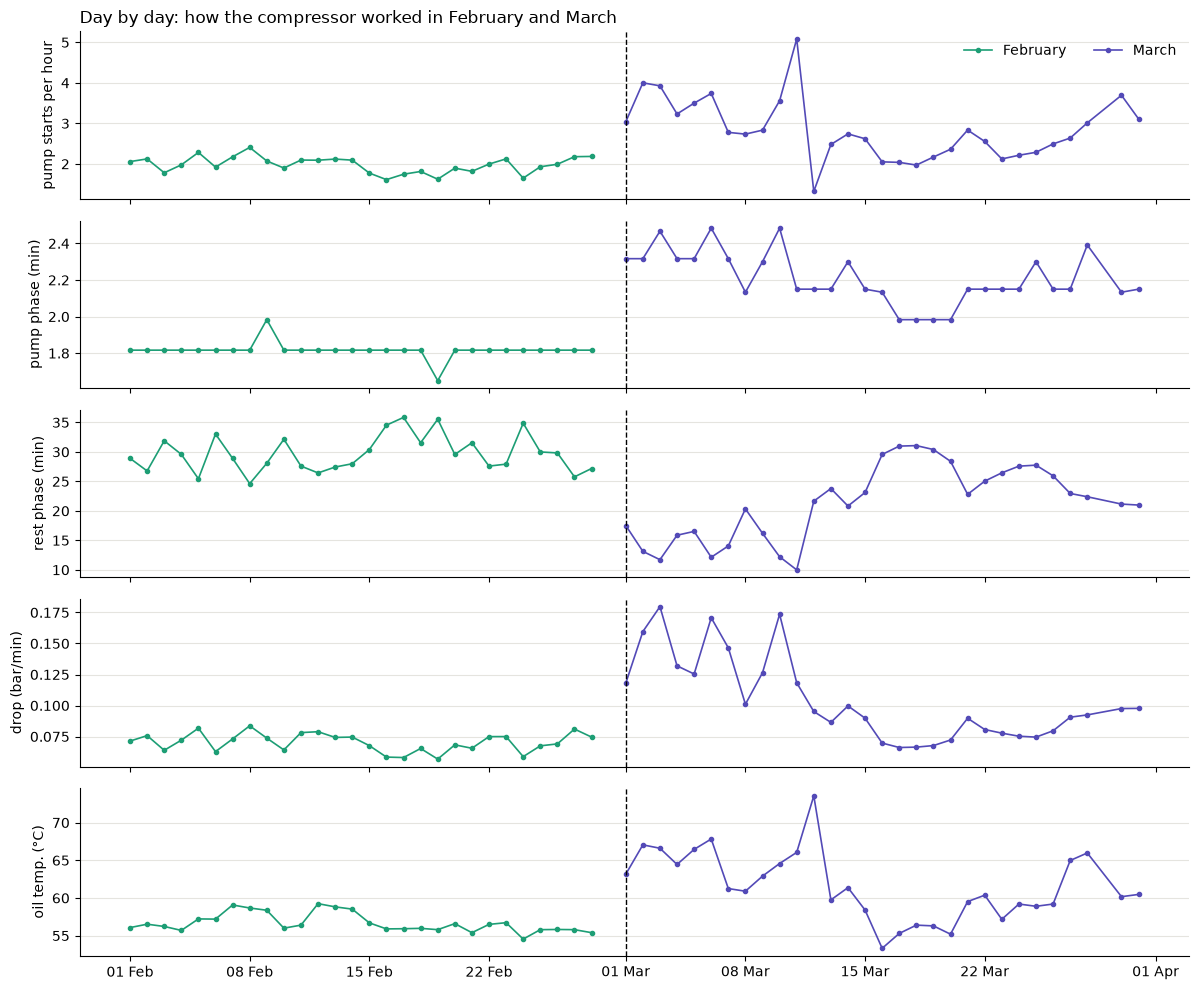

In [14]:
pumps["day"] = pd.to_datetime(pumps["start"]).dt.floor("D")
daily = pumps.groupby("day").agg(cycles=("pump_minutes", "size"), pump_minutes=("pump_minutes", "median"),
                                 rest_minutes=("rest_minutes", "median"), drop_per_minute=("drop_per_minute", "median"))
daily["pump_starts_per_hour"] = daily["cycles"] / (pumps.groupby("day")[["pump_minutes", "rest_minutes"]].sum().sum(axis=1) / 60)
daily["oil_temperature"] = df_sensors.groupby(df_sensors["timestamp"].dt.floor("D"))["Oil_temperature"].median()

fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
panels = [("pump_starts_per_hour", "pump starts per hour"), ("pump_minutes", "pump phase (min)"), ("rest_minutes", "rest phase (min)"),
          ("drop_per_minute", "drop (bar/min)"), ("oil_temperature", "oil temp. (°C)")]
for ax, (column, label) in zip(axes, panels):
    for month, color in MONTH_COLORS.items():
        part = daily[daily.index.month_name() == month]
        ax.plot(part.index, part[column], marker="o", markersize=3, color=color, linewidth=1.2, label=month)
    ax.axvline(pd.Timestamp(split_table.set_index("split").loc["validation", "from"]), color="black", linestyle="--", linewidth=1)
    ax.set_ylabel(label)
    ax.grid(axis="y", color="#E5E4DF")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].legend(frameon=False, ncol=2)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].set_title("Day by day: how the compressor worked in February and March", loc="left")
plt.tight_layout()
plt.show()

In [15]:
halves = pd.Series(np.where(daily.index.month == 2, "February", np.where(daily.index.day <= 15, "1 to 15 March", "16 to 31 March")), index=daily.index)
display(daily.groupby(halves)[["pump_starts_per_hour", "pump_minutes", "rest_minutes", "drop_per_minute", "oil_temperature"]].median()
        .reindex(["February", "1 to 15 March", "16 to 31 March"]).round(3))
print(f"Correlation between pump starts per hour and oil temperature, day by day: {daily['pump_starts_per_hour'].corr(daily['oil_temperature']):.2f}")

,pump_starts_per_hour,pump_minutes,rest_minutes,drop_per_minute,oil_temperature
February,1.993,1.817,29.237,0.072,56.312000
1 to 15 March,3.037,2.317,16.200,0.125,64.449997
16 to 31 March,2.362,2.150,26.450,0.078,59.200001


Correlation between pump starts per hour and oil temperature, day by day: 0.66


> **What we see:**
>
> - In **February** the compressor works in a steady rhythm: the pump phase is almost the same length every day.
> - Right at the start of **March** something changes: the compressor starts pumping clearly more often, each pump phase gets longer, the rest phases get shorter, and the pressure falls faster while resting. In the second half of March it moves back towards February, but not all the way, and at the end of March it climbs again.
> - No leak is reported in March, so we cannot know why. It could be more air use, a changed setting after the train stood still on 29 February (no data that day, see notebook 1.1), or a small problem nobody wrote down.
> - The **oil temperature** level moves too: it is higher in March, and it goes up and down with how hard the compressor works. Summer will be warmer still.
>
> **What this means for us:**
>
> 1. The models learn "normal" from February only, as planned. If we also trained on early March, a model could learn that "pumping a lot" is normal, and that is exactly what a leak looks like.
> 2. March stays the validation month. The alarm limit is set on March in notebook 5.1, with the budget of at most 1 false alarm per week. Because early March already looks a little unusual, the limit will probably end up more careful (higher). We will see in notebook 5.2 whether that costs warnings, and we will say so.
> 3. **Decision: the models do not get the raw oil temperature level.** It moves with the season and the workload, so a warm summer day would look "unusual" to a model that only saw February. Instead they get how much the oil temperature changed within the window.

## Signals That Move Together

### Correlation of the 7 Numbers (February)

> Each square shows the correlation of two signals in February: dark green near 1 (they move together), dark orange near -1 (they move opposite), white near 0.

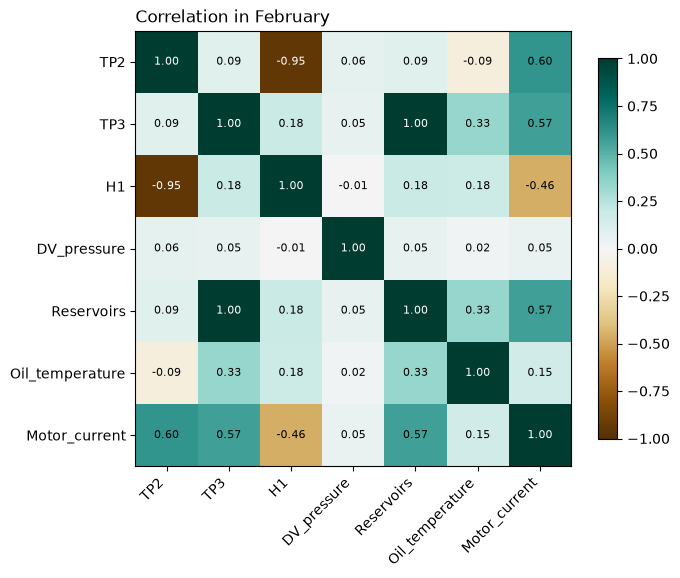

In [16]:
correlation = df_sensors.loc[df_sensors["month"] == "February", ANALOG_COLUMNS].corr()
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(correlation, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(ANALOG_COLUMNS)), ANALOG_COLUMNS, rotation=45, ha="right")
ax.set_yticks(range(len(ANALOG_COLUMNS)), ANALOG_COLUMNS)
for row in range(len(ANALOG_COLUMNS)):
    for column in range(len(ANALOG_COLUMNS)):
        value = correlation.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.7 else "black")
fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Correlation in February", loc="left")
plt.tight_layout()
plt.show()

### On/Off Signals That Agree

> For the on/off signals, we count how often two of them have the same value.

In [17]:
february = df_sensors[df_sensors["month"] == "February"]
pairs = [("COMP", "MPG", "same value"), ("COMP", "DV_eletric", "opposite value")]
for first, second, kind in pairs:
    differ = int((february[first] != february[second]).sum()) if kind == "same value" else int((february[first] == february[second]).sum())
    print(f"{first} and {second} ({kind}): {differ:,} exceptions in {len(february):,} February readings")
print(f"Largest difference between TP3 and Reservoirs in February: {(february['TP3'] - february['Reservoirs']).abs().max():.3f} bar")

COMP and MPG (same value): 0 exceptions in 214,850 February readings
COMP and DV_eletric (opposite value): 2 exceptions in 214,850 February readings
Largest difference between TP3 and Reservoirs in February: 0.014 bar


> **What we see:** `TP3` and `Reservoirs` move as one, always less than 0.02 bar apart (the description says the tank pressure should be close to the panel pressure). `COMP` and `MPG` have the same value in every February reading, and `COMP` is the opposite of `DV_eletric` in all but a couple of readings.
>
> **Decision: we keep all 15 signals.** Two signals that always move together are still useful: if a leak sits between the panel and the tanks, `TP3` and `Reservoirs` could suddenly differ, and that difference is itself something unusual for the models to notice.

## Result

### Final Result

> The checks of this notebook: only February and March were loaded, and `DV_eletric` agrees with the motor current, so it is safe to find the pump phases with it.

In [18]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (2 checks)


## Summary

> **How a healthy compressor works:** it runs in pump cycles. It rests while the train uses air and the pressure slowly falls, then pumps for about 2 minutes to fill the tanks again. The motor current shows three states: off, turning without pumping, and pumping. `DV_eletric` reliably shows the pump phases.
>
> **Decisions for notebook 3.1:**
>
> 1. **Windows of 60 minutes, one every 5 minutes.** A 30-minute window rarely holds a full pump cycle; 60 minutes holds one most of the time.
> 2. **Windows with a gap inside are left out** (from notebook 1.1).
> 3. **Oil temperature as a change, not as a level.** Its level moves with the season and the workload.
> 4. **All 15 signals stay.** Signals that always move together can show a problem when they stop doing so.
> 5. **The "slow puncture" features for Isolation Forest** come from this notebook: how many pump starts, how long the pump and rest phases are, and how fast the pressure falls while resting.
>
> **A finding to remember:** the start of March already looks different from February (more pumping), with no reported leak. The models still learn from February only, and the alarm limit is set on March, as planned.
>
> **Next:** `notebooks/3_preprocessing/3.1_make_windows.ipynb`